### **Investigation Of White Dwarfs With Various Equations of State Under General Relativity**

In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy import integrate
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from numba import njit

In [2]:
G = 6.673 * 10**-11
c = 3 * 10**8
h = 6.626 * 10**-34
ep_0 = 8.854 * 10**-12
q = 1.602 * 10**-19
k_e = 1/(4 * np.pi * ep_0)
k_b = 1.3806 * 10**-23
Mp = 1.673 * 10**-27
Me = 9.109 * 10**-31
mu_e = 2
A = np.pi/3 * (h/(Me * c))**(-3) * Me * c**2
B = 8 * np.pi * Mp/3 * (h/(Me * c))**(-3)
Msol= 1.989 * 10**30
Re = 6378 * 10**3


### **Electron Degenerate, Newtonian White Dwarfs**

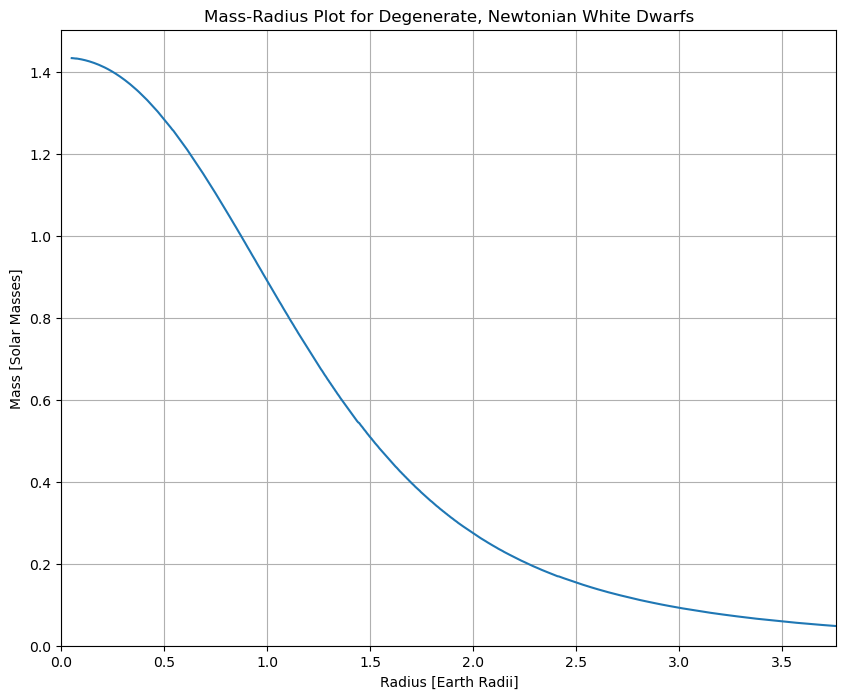

In [3]:
rho_arr = np.logspace(7, 15, 10**3)
xc_arr = (rho_arr/(mu_e * B))**(1/3)
yc_arr = np.sqrt(xc_arr**2 + 1)
alpha_arr = np.sqrt(2 * A/(np.pi * G)) * (1/(B * mu_e * yc_arr))


z_span = (0.001, 20)
z_eval = np.linspace(0.001, 20, 10**4)

@njit

def newt_WD(z, w, y_c):
    Q, dQdz = w
    d2Qdz2 = -(2/z) * dQdz - (Q**2 - 1/y_c**2)**(3/2)
    return [dQdz, d2Qdz2]

def surface(z, w, y_c):
        Q = w[0]
        return Q - 1/y_c

surface.terminal = True 
surface.direction = -1


def MR_relation_NWD():
    M_newtWD = []
    R_newtWD = []
    z1 = 0.001
    Q1_arr = 1 - 1/6 * (1 - 1/yc_arr**2)**(3/2) * z1**2
    dQdz1_arr = -1/3 * (1 - 1/yc_arr**2)**(3/2) * z1
    np.seterr(invalid='ignore')
    for i in range(len(rho_arr)):
        y0 = [Q1_arr[i], dQdz1_arr[i]]
        sol = solve_ivp(newt_WD, z_span, y0, events=surface, t_eval=z_eval, args=(yc_arr[i],))
        z_s = sol.t[-1]
        dQdz_s = sol.y[1][-1]
        R = alpha_arr[i] * z_s
        M = 4 * np.pi/(B * mu_e)**2 * (2 * A/(np.pi * G))**(3/2) * (-z_s**2 * dQdz_s)
        M_newtWD.append(M/Msol)
        R_newtWD.append(R/Re)

    return [R_newtWD, M_newtWD]

R_NWD, M_NWD = MR_relation_NWD()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD)
plt.title('Mass-Radius Plot for Degenerate, Newtonian White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD))
plt.ylim(bottom=0)
plt.grid()


In [4]:
a = (10**15/(mu_e * B))**(1/3)

In [5]:
np.sqrt(a**2 + 1)

np.float64(79.82618496588861)

### **Coloumb Corrections**

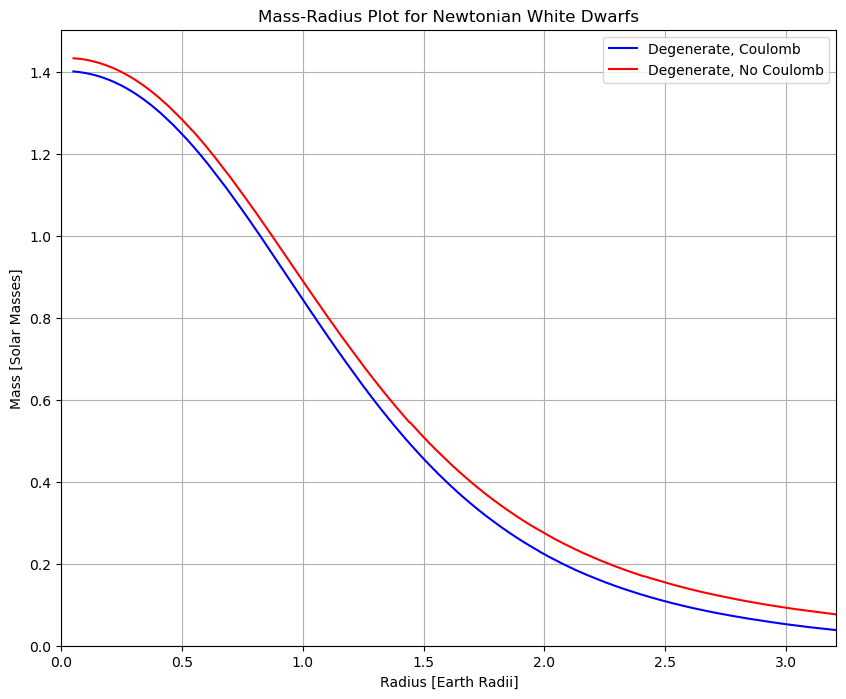

In [6]:
Z = (1/12 + 1/16)**-1
K = -3/10 * (4 * np.pi/3)**(1/3) * k_e * Z**(2/3) * q**2/(Mp * mu_e)**(4/3)

@njit

def newt_WD_col(z, w, y_c):
    Q, dQdz = w
    d2Qdz2 = (-8 * A/(B *mu_e) * (Q**2 - 1/y_c**2)**(3/2) + 
              4 * K *(B * mu_e)**(1/3) * y_c/(y_c**2 * Q**2 - 1)**(3/2) * (dQdz)**2) * (8 * A/(B * mu_e) + 4 * K * (B * mu_e)**(1/3) * y_c * Q/np.sqrt(y_c**2 * Q**2 -1))**(-1) - 2/z * dQdz
    return [dQdz, d2Qdz2]

def MR_relation_NWD_c():
    M_newtWD_c = []
    R_newtWD_c = []
    z1 = 0.001
    Q1_arr = 1 - (4 * A)/(3 * B * mu_e) * (1 - 1/yc_arr**2)**(3/2) * ((8 * A)/(B * mu_e) + (4 * K * (B *mu_e)**(1/3) * yc_arr)/np.sqrt(yc_arr**2 - 1))**(-1) * z1**2
    dQdz1_arr = - (8 * A)/(3 * B * mu_e) * (1 - 1/yc_arr**2)**(3/2) * ((8 * A)/(B * mu_e) + (4 * K * (B *mu_e)**(1/3) * yc_arr)/np.sqrt(yc_arr**2 - 1))**(-1) * z1
    np.seterr(invalid='ignore')
    for i in range(len(rho_arr)):
        y0 = [Q1_arr[i], dQdz1_arr[i]]
        sol = solve_ivp(newt_WD_col, z_span, y0, events=surface, t_eval=z_eval , args=(yc_arr[i],))
        z_s = sol.t[-1]
        dQdz_s = sol.y[1][-1]
        R = alpha_arr[i] * z_s
        rho = B * mu_e * yc_arr[i]**3 * (sol.y[0]**2 - 1/yc_arr[i]**2)**(3/2)
        r = alpha_arr[i] * sol.t
        M = 4 * np.pi * integrate.simpson(rho * r**2, x=r)
        M_newtWD_c.append(M/Msol)
        R_newtWD_c.append(R/Re)

    return [R_newtWD_c, M_newtWD_c]

R_NWD_c, M_NWD_c = MR_relation_NWD_c()


plt.figure(figsize=(10,8))
plt.plot(R_NWD_c, M_NWD_c, color='blue', label='Degenerate, Coulomb')
plt.plot(R_NWD, M_NWD, color='red', label='Degenerate, No Coulomb')
plt.title('Mass-Radius Plot for Newtonian White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()
        

### **General Relativistic Treatment**

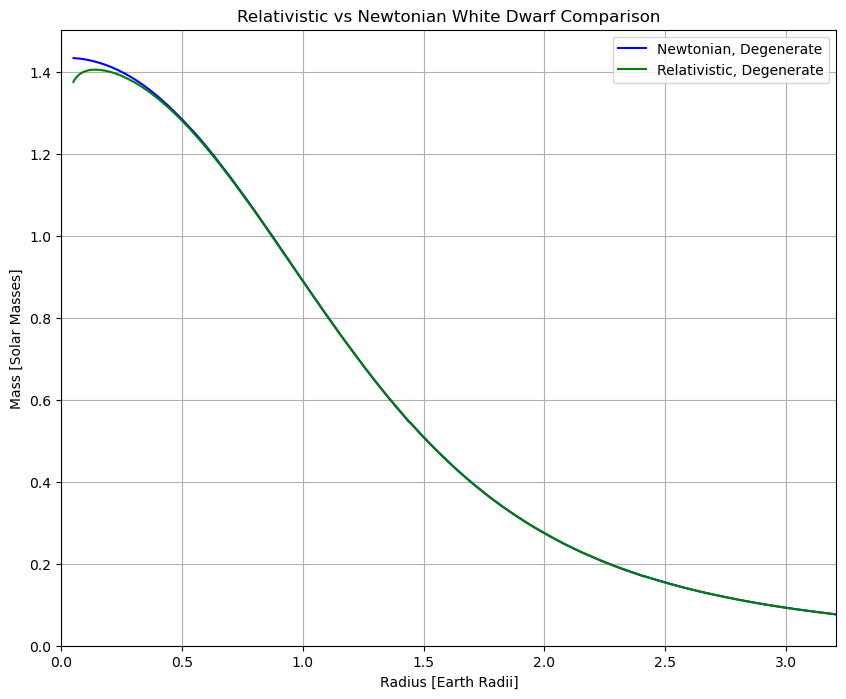

In [7]:
@njit
def GR_WD(r, w):
    x, m = w
    rho = mu_e * B * x**3
    P = A * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x))
    dxdr = - (G * m * rho)/r**2 * (1 + P/(rho * c**2)) * (1 + 4 * np.pi * r**3 * P/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (1 + x**2)**(1/2)/(8 * A * x**4)    
    dmdr = 4 * np.pi * r**2 * rho
    return [dxdr, dmdr]

r_span = (0.001, 4*Re)
r_eval = np.linspace(0.001, 4*Re, 10**4)

def surface_r(r, w):
        x = w[0] 
        return x 

surface_r.terminal = True 
surface_r.direction = -1


def MR_relation_GRWD():
    M_genrelWD = []
    R_genrelWD = []
    Pc_arr = A * (xc_arr * (2 * xc_arr**2 - 3) * (1 + xc_arr**2)**(1/2) + 3 * np.arcsinh(xc_arr))
    r1 = 0.001
    x1_arr = xc_arr - (2 * np.pi * G * rho_arr**2)/3 * (1 + Pc_arr/(rho_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (1 + xc_arr**2)**(1/2)/(8 * A * xc_arr**4) * r1**2
    m1_arr = 4 * np.pi * rho_arr * r1**3/3
    for i in range(len(rho_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol = solve_ivp(GR_WD, r_span, y0, events=surface_r, t_eval=r_eval, method='Radau')
        R = sol.t[-1]
        M = sol.y[1][-1]
        M_genrelWD.append(M/Msol)
        R_genrelWD.append(R/Re)
    return [R_genrelWD, M_genrelWD]


R_GRWD, M_GRWD = MR_relation_GRWD()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD, color='blue', label = 'Newtonian, Degenerate')
plt.plot(R_GRWD, M_GRWD, color = 'green', label = 'Relativistic, Degenerate')
plt.title('Relativistic vs Newtonian White Dwarf Comparison')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()

In [8]:
M_GRWD_max = max(M_GRWD)
print('Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf:', round(M_GRWD_max,4), 'Msol')

Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf: 1.4058 Msol


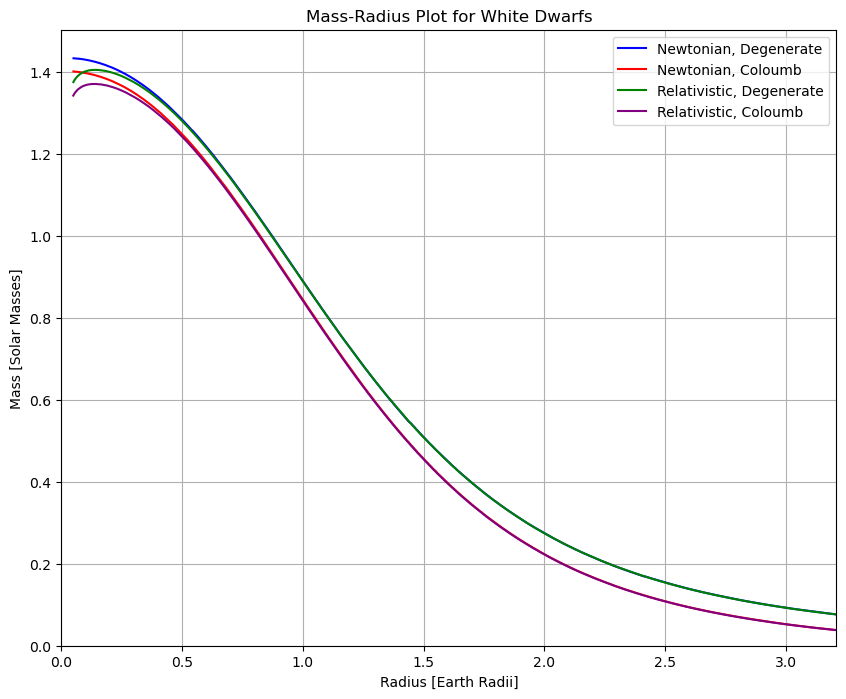

In [9]:
@njit

def GR_WD_c(r, w):
    x, m = w
    rho = mu_e * B * x**3
    P = A * (x * (2 * x**2 - 3) * (1 + x**2)**(1/2) + 3 * np.arcsinh(x)) + K * (mu_e * B)**(4/3) * x**4
    dxdr = - (G * m * rho)/r**2 * (1 + P/(rho * c**2)) * (1 + 4 * np.pi * r**3 * P/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (8 * A * x**4/(1 + x**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * x**3)**(-1)
    dmdr = 4 * np.pi * r**2 * rho
    return [dxdr, dmdr]

def MR_relation_GRWD_c():
    M_genrelWD_c = []
    R_genrelWD_c = []
    Pc_arr = A * (xc_arr * (2 * xc_arr**2 - 3) * (1 + xc_arr**2)**(1/2) + 3 * np.arcsinh(xc_arr)) + K * (mu_e * B)**(4/3) * xc_arr**4
    r1 = 0.001
    x1_arr = xc_arr - (2 * np.pi * G * rho_arr**2)/3 * (1 + Pc_arr/(rho_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (8 * A * xc_arr**4/(1 + xc_arr**2)**(1/2) + 4 * K * (mu_e * B)**(4/3) * xc_arr**3)**(-1) * r1**2
    m1_arr = 4 * np.pi * rho_arr * r1**3/3
    for i in range(len(rho_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol = solve_ivp(GR_WD_c, r_span, y0, events=surface_r, t_eval=r_eval, method='Radau')
        R = sol.t[-1]
        M = sol.y[1][-1]
        M_genrelWD_c.append(M/Msol)
        R_genrelWD_c.append(R/Re)
    return [R_genrelWD_c, M_genrelWD_c]

R_GRWD_c, M_GRWD_c = MR_relation_GRWD_c()

plt.figure(figsize=(10,8))
plt.plot(R_NWD, M_NWD, color='blue', label = 'Newtonian, Degenerate')
plt.plot(R_NWD_c, M_NWD_c, color='red', label = 'Newtonian, Coloumb')
plt.plot(R_GRWD, M_GRWD, color = 'green', label = 'Relativistic, Degenerate')
plt.plot(R_GRWD_c, M_GRWD_c, color = 'purple', label = 'Relativistic, Coloumb')
plt.title('Mass-Radius Plot for White Dwarfs')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_NWD_c))
plt.ylim(bottom=0)
plt.legend()
plt.grid()



In [10]:
M_GRWD_c_max = max(M_GRWD_c)
print('Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections:', round(M_GRWD_c_max,4), 'Msol')

Chandrasekhar mass of a relativistic, electron-degenerate carbon-oxygen white dwarf with coloumb corrections: 1.3714 Msol


### **Finite Temperature Correction with a Non-Degenerate Surface Layer**

In [11]:
z, t = sp.symbols('z t')

def F(y):
    return y * (y**2 + 1)**(1/2) * (2 * y**2 - 3) + 3 * sp.asinh(y)

rho_expr = mu_e * B * z**3 * (1 + np.pi**2 * (1 + 2 * z**2) / (2 * z**4) * (k_b * t / (Me * c**2))**2)
P_expr = A * (F(z) + 4 * np.pi**2 * z * (1 + z**2)**(0.5) * (k_b * t / (Me * c**2))**2) + K * (rho_expr)**sp.Rational(4,3)
dPdx_expr = P_expr.diff(z, 1)

compute_P = sp.lambdify((z, t), P_expr, 'numpy')
compute_rho = sp.lambdify((z, t), rho_expr, 'numpy')
compute_dPdx = sp.lambdify((z, t), dPdx_expr, 'numpy')


def P(y, T): 
    return compute_P(y, T)


def rho(y, T): 
    return compute_rho(y, T)


def dPdx(y, T): 
    return compute_dPdx(y, T)


In [12]:
x_arr = np.linspace(0.5, 50, 10**3)
D = -9/10 * (4 * np.pi/3)**(1/3) * k_e * Z**(2/3) * q**2

def GR_WD_T(r, w, T0):
    x, m = w
    dxdr = - (G * m * rho(x, T0))/r**2 * (1 + P(x, T0)/(rho(x, T0) * c**2)) * (1 + 4 * np.pi * r**3 * P(x, T0)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1) * (dPdx(x, T0))**(-1)
    dmdr = 4 * np.pi * r**2 * rho(x, T0)
    return [dxdr, dmdr]

def WD_env(r, w, C):
    rho, m = w
    drhodr = - (13 * G * m * rho**(9/13))/(17 * C * r**2) * (1 + C * rho**(4/13)/c**2) * (1 + 4 * np.pi * r**3 * C * rho**(17/13)/(m * c**2)) * (1 - 2 * G * m/(r * c**2))**(-1)
    dmdr = 4 * np.pi * rho * r**2
    return [drhodr, dmdr]

def core_boundary(T0):
    def core_eq(x):
        E_F = Me * c**2 * (np.sqrt(x**2 + 1) -1)
        E_c = D * (rho(x, T0)/(mu_e * Mp))**(1/3)
        return E_F + E_c - k_b * T0
    root = brentq(core_eq, 0.01, 0.5)
    return root

def core(r, w, T0):
    x = w[0]
    return x - core_boundary(T0)

core.terminal = True

def envelope(r, w, C):
    rho = w[0]
    return rho - 1e-3

envelope.terminal = True 
envelope.direction = -1

def MR_relation_T(T0):
    M_GRWD_T = []
    R_GRWD_T = []

    Pc_arr = P(x_arr, T0)

    rhoc_arr = rho(x_arr, T0)

    dPdxc_arr = dPdx(x_arr, T0)

    r1 = 0.001

    x1_arr = x_arr - (2 * np.pi * G * rhoc_arr**2)/3 * (1 + Pc_arr/(rhoc_arr * c**2)) * (1 + 3 * Pc_arr/c**2) * (dPdxc_arr)**(-1) * r1**2

    m1_arr =  4 * np.pi * rhoc_arr * r1**3/3

    x0 = core_boundary(T0)

    P0 = P(x0, T0)
    rho0 = rho(x0, T0)
    C = P0/(rho0)**(17/13)

    for i in range(len(x_arr)):
        y0 = [x1_arr[i], m1_arr[i]]
        sol_core = solve_ivp(GR_WD_T, r_span, y0, events=core, args=(T0,), method='Radau', max_step=1e3)
        r0 = sol_core.t_events[0][0]
        m0 = sol_core.y_events[0][0][-1]
        env_span = (r0, 4*Re)
        sol_env = solve_ivp(WD_env, env_span, y0=[rho0, m0], events=envelope, args=(C,), method='Radau', max_step=1e4)
        
        M = sol_env.y_events[0][0][-1]
        R = sol_env.t_events[0][0]
        M_GRWD_T.append(M/Msol)
        R_GRWD_T.append(R/Re)
    return [R_GRWD_T, M_GRWD_T]
        

R_5e7, M_5e7 = MR_relation_T(5*10**7)

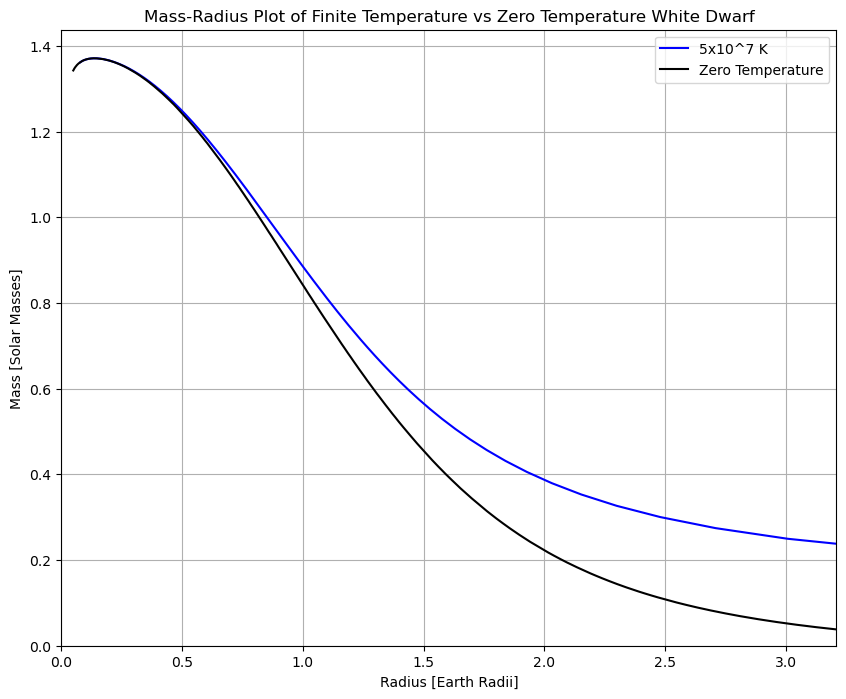

In [13]:
plt.figure(figsize=(10,8))
plt.plot(R_5e7, M_5e7, color = 'blue', label='5x10^7 K')
plt.plot(R_GRWD_c, M_GRWD_c, color='black', label='Zero Temperature')
plt.title('Mass-Radius Plot of Finite Temperature vs Zero Temperature White Dwarf')
plt.xlabel('Radius [Earth Radii]')
plt.ylabel('Mass [Solar Masses]')
plt.xlim(0, max(R_GRWD_c))
plt.ylim(bottom=0)
plt.grid()
plt.legend()
plt.show()

### **Nuclear Equation of State at Higher Densities**